# Response of the redshift-space power spectrum

This notebook computes the response of the redshift-space power spectrum to each parameter.

A survey observes the spectrum as a function of the wave number and of $\mu$, the cosine of the angle to the line of sight. Two effects make it anisotropic. Peculiar velocities add the Kaiser factor,

$$
P_g(k, \mu) = (b + f \mu^2)^2 P(k),
$$

and the survey converts redshifts and angles into distances with a reference cosmology, which rescales the true wave numbers (the Alcock-Paczynski effect):

$$
P_\mathrm{obs}(k_\mathrm{ref}, \mu_\mathrm{ref}) = \frac{P_g(k, \mu)}{q_\perp^2 q_\parallel}, \qquad
q_\perp = \frac{D_A}{D_{A,\mathrm{ref}}}, \qquad
q_\parallel = \frac{H_\mathrm{ref}}{H} .
$$

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from discoeb import LCDM, matter_power_spectrum, solve_eb

REDSHIFT = 1.0
K = np.geomspace(1.0e-4, 1.0, 128)  # wave numbers of the solve, 1/Mpc
K_REF = K[4:-4]  # the map's wave numbers, whose rescaled values stay inside K
MU = np.linspace(0.0, 1.0, 65)

We use as a reference the Planck 2018 best fit, given by $\Omega_m$, $\Omega_b$ and $H_0$, with five cosmological parameters plus the galaxy bias, $b = 1.5$.

In [2]:
h = 0.6732117
PLANCK = dict(
    Omega_m=(0.02238280 + 0.1201075) / h**2,
    Omega_b=0.02238280 / h**2,
    H_0=100.0 * h,
    A_s=2.100549e-9,
    n_s=0.9660499,
    T_cmb=2.7255,
    Y_He=0.2454006,
    N_eff=3.046,
)
PARAMETERS = {  # key: label, the last being the galaxy bias
    "H_0": "H_0",
    "Omega_m": r"\Omega_m",
    "Omega_b": r"\Omega_b",
    "N_eff": r"N_\mathrm{eff}",
    "n_s": "n_s",
    "bias": "b",
}
theta = jnp.asarray([PLANCK[key] for key in list(PARAMETERS)[:-1]] + [1.5])

`solve_eb` integrates in the scale factor and differentiates at fixed scale factors.

In [3]:
A_SAMPLE = 1.0 / (1.0 + REDSHIFT)

`matter_power_spectrum` turns the contrasts into $P$, and the contrasts and their rates give the growth rate

$$
f = -\frac{h'/2 + f_b \theta_b}{a H \, \delta}, \qquad f_b = \frac{\omega_b}{\omega_c + \omega_b},
$$

`aH` gives the expansion rate, and the comoving distance is $\tau_0 - \tau(a)$.

In [4]:
def solve_matter_power_spectrum(cosmology):
    """``P(k)``, the growth rate ``f(k)``, the comoving distance and ``a H`` at the redshift."""

    values = solve_eb(
        cosmology,
        K,
        [A_SAMPLE, 1.0],
        keep=("delta_c", "delta_b", "h_prime", "theta_b", "aH", "tau"),
    )
    delta_c, delta_b, h_prime, theta_b, aH, tau = values[
        0, :, :, 0
    ]  # each (k,), at the redshift
    tau0 = values[0, -1, 0, -1]  # the conformal time today

    pk = matter_power_spectrum(
        K,
        delta_c=delta_c,
        delta_b=delta_b,
        omega_c=cosmology.omega_c,
        omega_b=cosmology.omega_b,
        A_s=cosmology.A_s,
        n_s=cosmology.n_s,
        k_p=cosmology.k_p,
    )
    f_b = cosmology.omega_b / (cosmology.omega_c + cosmology.omega_b)
    delta = (1.0 - f_b) * delta_c + f_b * delta_b
    growth_rate = -(0.5 * h_prime + f_b * theta_b) / (aH * delta)
    return pk, growth_rate, tau0 - tau[0], aH[0]

The survey assumes the reference cosmology's distance and expansion rate:

In [5]:
_, _, distance_ref, aH_ref = solve_matter_power_spectrum(
    LCDM.from_density_parameters(**PLANCK)
)

A reference pair $(k_\mathrm{ref}, \mu_\mathrm{ref})$ maps to the true spectrum:

$$
k = \frac{k_\mathrm{ref}}{q_\perp} \sqrt{1 + \mu_\mathrm{ref}^2 \left(\frac{q_\perp^2}{q_\parallel^2} - 1\right)},
\qquad
\mu = \mu_\mathrm{ref} \, \frac{q_\perp}{q_\parallel} \left[1 + \mu_\mathrm{ref}^2 \left(\frac{q_\perp^2}{q_\parallel^2} - 1\right)\right]^{-1/2} .
$$

In [6]:
def observed_power(theta):
    """``P_obs(k_ref, mu_ref)`` in Mpc^3, ``(len(K_REF), len(MU))``."""

    *cosmological, bias = theta
    pk, growth_rate, distance, aH = solve_matter_power_spectrum(
        LCDM.from_density_parameters(
            **{**PLANCK, **dict(zip(PARAMETERS, cosmological))}
        )
    )
    q_perp, q_par = distance / distance_ref, aH_ref / aH
    stretch = jnp.sqrt(1.0 + MU**2 * ((q_perp / q_par) ** 2 - 1.0))
    k = K_REF[:, None] / q_perp * stretch  # the true wave number and angle
    mu = MU * q_perp / q_par / stretch
    pk = jnp.exp(jnp.interp(jnp.log(k), np.log(K), jnp.log(pk)))
    growth_rate = jnp.interp(jnp.log(k), np.log(K), growth_rate)
    return (bias + growth_rate * mu**2) ** 2 * pk / (q_perp**2 * q_par)

One `jax.jacfwd` gives $\partial \ln P_\mathrm{obs} / \partial \ln p$ over the $(k, \mu)$ plane.

In [7]:
power = observed_power(theta)
jacobian = jax.jacfwd(observed_power)(theta)  # (k, mu, parameter)
response = np.asarray(theta * jacobian / power[..., None])  # d ln P / d ln p

In [8]:
print(f"d ln P_obs / d ln p at z = {REDSHIFT}, across (mu = 0) and along (mu = 1)")
print(f"{'k [1/Mpc]':>10}  {'mu':>3}" + "".join(f"{key:>9}" for key in PARAMETERS))
for i in range(6, len(K_REF), 22):
    for j in (0, -1):
        row = "".join(f"{v:9.3f}" for v in response[i, j])
        print(f"{K_REF[i]:10.3e}  {MU[j]:3.0f}{row}")

d ln P_obs / d ln p at z = 1.0, across (mu = 0) and along (mu = 1)
 k [1/Mpc]   mu      H_0  Omega_m  Omega_b    N_eff      n_s     bias
 2.065e-04    0   -0.027   -0.991    0.000   -0.001   -5.303    2.000
 2.065e-04    1   -0.029   -0.710    0.000   -0.001   -5.303    1.262
 1.018e-03    0    0.031   -0.946    0.000   -0.013   -3.762    2.000
 1.018e-03    1    0.024   -0.674    0.000   -0.013   -3.762    1.262
 5.021e-03    0    0.403   -0.649   -0.003   -0.097   -2.221    2.000
 5.021e-03    1    0.371   -0.441   -0.003   -0.098   -2.221    1.263
 2.476e-02    0    1.382    0.615   -0.297   -0.297   -0.679    2.000
 2.476e-02    1    1.348    0.577   -0.297   -0.297   -0.679    1.263
 1.221e-01    0    2.256    1.613   -0.740   -0.552    0.862    2.000
 1.221e-01    1    2.375    1.568   -0.740   -0.553    0.862    1.263
 6.019e-01    0    2.892    2.259   -0.764   -0.558    2.404    2.000
 6.019e-01    1    2.877    2.013   -0.764   -0.558    2.404    1.263


Each parameter has one polar "eye". The angle to the line of sight goes around, with the line of sight pointing up, and $\log k$ increases outwards.

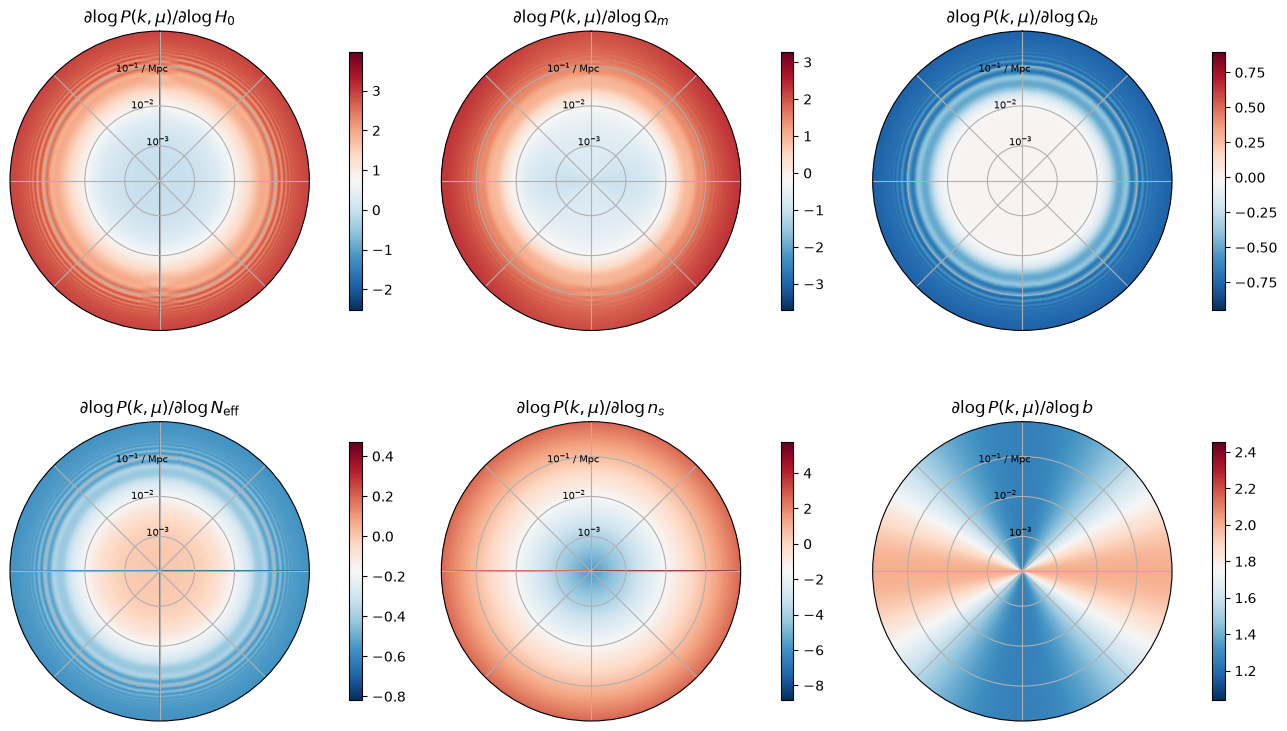

In [9]:
# One eye per parameter: the angle to the line of sight around, log k outwards.
angle = np.arccos(MU)
angle = np.concatenate(
    [angle, np.pi - angle[::-1], np.pi + angle, 2 * np.pi - angle[::-1]]
)
fig, axes = plt.subplots(2, 3, figsize=(13, 8.5), subplot_kw={"projection": "polar"})
for i, (ax, label) in enumerate(zip(axes.flat, PARAMETERS.values())):
    quadrant = response[..., i]
    eye = np.concatenate([quadrant, quadrant[:, ::-1], quadrant, quadrant[:, ::-1]], 1)
    centre = np.median(quadrant)
    limit = 3.0 * np.std(quadrant) + 1.0e-3
    mesh = ax.pcolormesh(
        angle,
        np.log10(K_REF),
        eye,
        cmap="RdBu_r",
        vmin=centre - limit,
        vmax=centre + limit,
        shading="gouraud",
    )
    fig.colorbar(mesh, ax=ax, shrink=0.6, pad=0.1)
    ax.set_theta_zero_location("N")
    ax.set_xticklabels([])
    ax.set_rticks([-3, -2, -1])
    ax.set_yticklabels([r"$10^{-3}$", r"$10^{-2}$", r"$10^{-1}$ / Mpc"], size=7)
    ax.set_title(rf"$\partial \log P(k, \mu) / \partial \log {label}$")
fig.tight_layout()
plt.show()